# 04 - Feature Engineering, Audit, and Preprocessing

**Questions addressed:**
1. Do feature files adhere strictly to expected schemas and value ranges?
2. Are features correct under independent recomputation on a random sample?
3. Are features provably leak-free (monotonic counts, age consistency, no future label overlap, time-shift invariance)?
4. How do features behave across missingness, skew, constants, redundancy, and drift?
5. Which preprocessing transforms are required, fitted strictly on the Train split?
6. Which features exhibit predictive association on Train and Validation dates (preserving Test split purity)?
7. Which feature sets are selected for M1/M2 (tabular) and M3 (graph-augmented) models?

**Rules:** Numbers computed from data files only. Strict test-split label protection. Markdown cells state questions and interpretation guidelines without hard-coded numbers.


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / 'ml').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA = ROOT / 'data'
PROC = DATA / 'processed'
FIG = ROOT / 'docs' / 'figures' / 'eda_features'
FIG.mkdir(parents=True, exist_ok=True)
print('Project root:', ROOT)


Project root: D:\DepRadar


In [2]:
HORIZON_MONTHS = 6
SAMPLE_PER_DATE = 500      # packages sampled per date for recomputation
CHECK_DATES = 4            # dates for recomputation: first train, last train, last val, NOW (if present)
PSI_BINS = 10
PSI_FLAG = 0.25
SEED = 0


In [3]:
import pandas as pd

# Find grid file and verify existence of required raw and processed inputs
grid_path = DATA / 'interim' / 'snapshot_grid.parquet'
if not grid_path.exists():
    grid_path = DATA / 'raw' / 'deps_dev' / 'snapshot_grid.parquet'

missing_items = []
if not grid_path.exists():
    missing_items.append("Snapshot grid missing (stage 1: pipelines/dataset_pipeline.py)")

raw_files = {
    'advisories_osv.parquet': DATA / 'interim' / 'advisories_osv.parquet',
    'package_versions.parquet': DATA / 'raw' / 'deps_dev' / 'package_versions.parquet',
    'dependents_by_T.parquet': DATA / 'raw' / 'deps_dev' / 'dependents_by_T.parquet',
}
for name, p in raw_files.items():
    if not p.exists():
        missing_items.append(f"Input table '{name}' missing at {p}")

t_folders = sorted([f for f in PROC.glob('T=*') if f.is_dir()]) if PROC.exists() else []
if not PROC.exists() or len(t_folders) == 0:
    missing_items.append("Snapshot folders data/processed/T=* missing (stage 9: build_snapshots.py)")
else:
    for f in t_folders:
        req = ['nodes.parquet', 'edges.parquet', 'features.parquet']
        if f.name != 'T=NOW':
            req.append('labels.parquet')
        for rf in req:
            if not (f / rf).exists():
                missing_items.append(f"{f.name} missing '{rf}'")
                break

if missing_items:
    raise RuntimeError("PREFLIGHT CHECK FAILED:\n" + "\n".join(missing_items))

grid = pd.read_parquet(grid_path)
print(f"Preflight passed: Grid loaded ({len(grid)} rows), {len(t_folders)} T=* folders validated.")


Preflight passed: Grid loaded (41 rows), 41 T=* folders validated.


In [4]:
import numpy as np, pandas as pd
from scipy.stats import rankdata

def psi(train_vals, other_vals, bins=10):
    """Population stability index of `other_vals` against `train_vals` using train quantile bins. NaN values are ignored
    (compare missing rates separately). Returns nan if either side is empty or the train values are (near) constant."""
    t = np.asarray(train_vals, float); o = np.asarray(other_vals, float)
    t, o = t[~np.isnan(t)], o[~np.isnan(o)]
    if len(t) == 0 or len(o) == 0:
        return float("nan")
    edges = np.unique(np.quantile(t, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return float("nan")
    edges[0], edges[-1] = -np.inf, np.inf
    pt = np.histogram(t, edges)[0] / len(t)
    po = np.histogram(o, edges)[0] / len(o)
    pt, po = np.clip(pt, 1e-6, None), np.clip(po, 1e-6, None)
    return float(((po - pt) * np.log(po / pt)).sum())

class Preprocessor:
    """Fit on the TRAIN split only; transform any split with the stored statistics.
    Steps: log1p on chosen columns (negatives clipped to 0) -> missing-flag columns (fixed at fit) -> median impute -> standardise."""
    def __init__(self, numeric, log1p_cols=()):
        self.numeric = list(numeric); self.log1p_cols = set(log1p_cols)

    def _base(self, df):
        X = df[self.numeric].astype(float).copy()
        for c in self.log1p_cols & set(self.numeric):
            X[c] = np.log1p(X[c].clip(lower=0))
        return X

    def fit(self, df):
        X = self._base(df)
        self.flag_cols_ = [c for c in self.numeric if X[c].isna().any()]
        self.median_ = X.median()
        Xf = X.fillna(self.median_)
        self.mean_ = Xf.mean()
        self.std_ = Xf.std(ddof=0).replace(0, 1.0).fillna(1.0)
        return self

    def transform(self, df):
        X = self._base(df)
        flags = pd.DataFrame({c + "_missing": X[c].isna().astype(float) for c in self.flag_cols_}, index=X.index)
        X = (X.fillna(self.median_) - self.mean_) / self.std_
        return pd.concat([X, flags], axis=1)

HORIZON_MONTHS = 6
SPLIT_MONTHS = {"train": ("2023-01", "2024-01"), "val": ("2024-07", "2024-09"),
                "test_a": ("2025-03", "2025-05"), "test_b": ("2025-11", "2026-04")}

def assign_splits(grid, split_months=SPLIT_MONTHS):
    g = grid.copy(); g["split"] = None
    for name, (a, b) in split_months.items():
        g.loc[(g.target_month >= a) & (g.target_month <= b), "split"] = name
    return g[g.split.notna()].reset_index(drop=True)

def apply_embargo(g, order=("train", "val", "test_a", "test_b"), horizon=HORIZON_MONTHS):
    """Drop leading dates of each split until next.T_min.date() > (prev.T_max + horizon months).date()."""
    g = g.copy(); dropped = []
    for prev, nxt in zip(order, order[1:]):
        if not (g.split == prev).any() or not (g.split == nxt).any():
            continue
        limit = (g.loc[g.split == prev, "T"].max() + pd.DateOffset(months=horizon)).date()
        while (g.split == nxt).any() and g.loc[g.split == nxt, "T"].min().date() <= limit:
            idx = g.loc[g.split == nxt, "T"].idxmin()
            dropped.append(g.loc[idx, "T"]); g = g.drop(idx)
    return g.reset_index(drop=True), dropped

RESULTS = []
def check(name, ok, detail=""):
    RESULTS.append((name, bool(ok), detail))
    print(("PASS " if ok else "FAIL "), name, ("| " + str(detail)) if detail else "")

def auc_rank(score, label):
    """AUC via ranks (ties get average rank). NaN scores are dropped. Returns nan if one class is missing."""
    score = np.asarray(score, float); y = np.asarray(label).astype(bool)
    m = ~np.isnan(score); score, y = score[m], y[m]
    n1, n0 = int(y.sum()), int((~y).sum())
    if n1 == 0 or n0 == 0:
        return float("nan")
    r = rankdata(score)
    return float((r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


In [5]:
# Assign temporal splits and compute embargo boundaries
labelled_grid = assign_splits(grid[~grid['is_now']])
use_grid, dropped_embargo = apply_embargo(labelled_grid)

train_grid = use_grid[use_grid.split == 'train'].reset_index(drop=True)
val_grid = use_grid[use_grid.split == 'val'].reset_index(drop=True)
test_a_grid = use_grid[use_grid.split == 'test_a'].reset_index(drop=True)
test_b_grid = use_grid[use_grid.split == 'test_b'].reset_index(drop=True)
now_row = grid[grid['is_now']].iloc[0]

train_dates = train_grid['T'].dt.date.astype(str).tolist()
val_dates = val_grid['T'].dt.date.astype(str).tolist()
test_dates = test_a_grid['T'].dt.date.astype(str).tolist() + test_b_grid['T'].dt.date.astype(str).tolist()

print(f"Assigned splits: train={len(train_dates)} dates, val={len(val_dates)} dates, "
      f"test_a={len(test_a_grid)} dates, test_b={len(test_b_grid)} dates.")
print(f"Embargo dropped {len(dropped_embargo)} date(s): {[str(d.date()) for d in dropped_embargo]}")
print("Dates used for label analysis (train + val only):", train_dates + val_dates)
print("Dates used label-free only (test splits):", test_dates)


Assigned splits: train=13 dates, val=2 dates, test_a=3 dates, test_b=6 dates.
Embargo dropped 1 date(s): ['2024-07-01']
Dates used for label analysis (train + val only): ['2023-01-02', '2023-01-29', '2023-02-27', '2023-04-03', '2023-05-01', '2023-05-29', '2023-07-03', '2023-07-31', '2023-08-28', '2023-10-02', '2023-10-30', '2023-11-27', '2024-01-01', '2024-07-29', '2024-09-02']
Dates used label-free only (test splits): ['2025-03-03', '2025-03-31', '2025-04-28', '2025-11-03', '2025-12-01', '2025-12-29', '2026-01-26', '2026-03-02', '2026-03-30']


## Part A - Schema and Ranges (All Dates, Label-Free)

**Question:** Do all processed snapshot `features.parquet` files match the project specification in column names, data types, and value range rules?
**How to read:** Schema tables list missing expected columns and extra columns per snapshot date. Range checks report violations across all packages at all dates.


In [6]:
# Define expected columns specification
EXPECTED_GROUPS = {
    'package': ['age_days', 'n_versions', 'n_release_versions', 'days_since_last_release',
                'releases_90d', 'releases_365d', 'median_gap_days_last20', 'n_deps_prod'],
    'popularity': ['log_dependents', 'dependents_delta_3m'],
    'advisory history': ['n_prior_adv', 'n_prior_adv_365d', 'days_since_last_adv',
                         'has_prior_adv', 'max_severity_ord', 'n_prior_critical_high'],
    'repository': ['has_repo', 'log_stars', 'log_forks', 'log_open_issues'],
    'graph': ['out_deg', 'in_deg', 'nb_out_mean_prior_adv', 'nb_out_max_prior_adv',
              'nb_out_frac_prior_adv', 'nb_in_mean_prior_adv', 'nb_in_max_prior_adv',
              'nb_in_frac_prior_adv', 'nb_out_mean_log_dependents', 'nb_in_mean_log_dependents']
}
ALL_EXPECTED = [col for cols in EXPECTED_GROUPS.values() for col in cols]

schema_diffs = []
for folder in t_folders:
    feats = pd.read_parquet(folder / 'features.parquet')
    nodes = pd.read_parquet(folder / 'nodes.parquet')
    match_pkg = (feats['package'].values == nodes['package'].values).all()
    match_idx = (feats['idx'].values == nodes['idx'].values).all()
    
    missing_cols = set(ALL_EXPECTED) - set(feats.columns)
    extra_cols = set(feats.columns) - set(ALL_EXPECTED) - {'package', 'idx'}
    if not (match_pkg and match_idx) or missing_cols or extra_cols:
        schema_diffs.append({
            'folder': folder.name, 'nodes_match': (match_pkg and match_idx),
            'missing': sorted(list(missing_cols)), 'extra': sorted(list(extra_cols))
        })

df_schema_audit = pd.DataFrame(schema_diffs)
check("schema check: package and idx match nodes.parquet for 100% of rows", all(r.get('nodes_match', True) for r in schema_diffs))
check("schema check: zero missing expected columns across all snapshot dates", not any(len(r.get('missing', [])) > 0 for r in schema_diffs))
print(f"Schema audit: {len(t_folders)} folders inspected. Extra columns present: {schema_diffs[0]['extra'] if schema_diffs else 'none'}")


PASS  schema check: package and idx match nodes.parquet for 100% of rows 
PASS  schema check: zero missing expected columns across all snapshot dates 
Schema audit: 41 folders inspected. Extra columns present: ['n_deps_prod_raw']


In [7]:
# Dtype table for one snapshot date
sample_f = pd.read_parquet(t_folders[0] / 'features.parquet')
group_map = {col: g for g, cols in EXPECTED_GROUPS.items() for col in cols}
group_map['package'] = 'identifier'; group_map['idx'] = 'index'; group_map['n_deps_prod_raw'] = 'extra'

df_dtypes = pd.DataFrame({
    'column': sample_f.columns,
    'group': [group_map.get(c, 'other') for c in sample_f.columns],
    'dtype': [str(sample_f[c].dtype) for c in sample_f.columns],
    'null_count': [int(sample_f[c].isna().sum()) for c in sample_f.columns]
})
print("Dtype table for snapshot T=2023-01-02 (head):\n", df_dtypes.head(10).to_string(index=False))


Dtype table for snapshot T=2023-01-02 (head):
                  column      group   dtype  null_count
                package identifier     str           0
                    idx      index   int64           0
               age_days    package float64         110
             n_versions    package float64           0
     n_release_versions    package float64           0
days_since_last_release    package float64         110
           releases_90d    package float64           0
          releases_365d    package float64           0
 median_gap_days_last20    package float64        1110
            n_deps_prod    package float64           0


In [8]:
# Range rules across snapshot dates (Part 1: Package, Popularity, Repo)
pkg_rules = [
    ('age_days >= 0', lambda df: df['age_days'] < 0),
    ('n_versions >= 1', lambda df: df['n_versions'] < 1),
    ('n_release_versions <= n_versions', lambda df: df['n_release_versions'] > df['n_versions']),
    ('days_since_last_release >= 0', lambda df: df['days_since_last_release'] < 0),
    ('days_since_last_release <= age_days', lambda df: df['days_since_last_release'] > df['age_days'] + 1e-4),
    ('releases_90d <= releases_365d <= n_versions', lambda df: (df['releases_90d'] > df['releases_365d']) | (df['releases_365d'] > df['n_versions'])),
    ('has_repo in {0,1} and repo cols 0 when has_repo==0', lambda df: (~df['has_repo'].isin([0, 1])) | ((df['has_repo'] == 0) & ((df['log_stars'] != 0) | (df['log_forks'] != 0) | (df['log_open_issues'] != 0)))),
    ('log_* >= 0', lambda df: (df['log_dependents'] < 0) | (df['log_stars'] < 0) | (df['log_forks'] < 0) | (df['log_open_issues'] < 0))
]

for name, cond in pkg_rules:
    total_viol, ex_pkgs = 0, []
    for folder in t_folders:
        f = pd.read_parquet(folder / 'features.parquet')
        bad = f[cond(f)]
        total_viol += len(bad)
        if len(bad) > 0 and len(ex_pkgs) < 5:
            ex_pkgs.extend(bad['package'].head(5 - len(ex_pkgs)).tolist())
    detail_msg = f"violations={total_viol}" + (f", examples={ex_pkgs}" if ex_pkgs else "")
    check(f"range check: {name}", total_viol == 0, detail=detail_msg)


PASS  range check: age_days >= 0 | violations=0
FAIL  range check: n_versions >= 1 | violations=134609, examples=['@fortawesome/pro-solid-svg-icons', '@fortawesome/pro-light-svg-icons', '@fortawesome/pro-regular-svg-icons', '@microchip/scf-common', '@microchip/scf-device']
PASS  range check: n_release_versions <= n_versions | violations=0
PASS  range check: days_since_last_release >= 0 | violations=0
PASS  range check: days_since_last_release <= age_days | violations=0
PASS  range check: releases_90d <= releases_365d <= n_versions | violations=0
PASS  range check: has_repo in {0,1} and repo cols 0 when has_repo==0 | violations=0
PASS  range check: log_* >= 0 | violations=0


In [9]:
# Range rules across snapshot dates (Part 2: Advisories, Graph, Consistency)
adv_rules = [
    ('n_prior_adv >= n_prior_adv_365d >= 0', lambda f, ed, lbl: (f['n_prior_adv_365d'] > f['n_prior_adv']) | (f['n_prior_adv'] < 0)),
    ('has_prior_adv == (n_prior_adv > 0)', lambda f, ed, lbl: f['has_prior_adv'] != (f['n_prior_adv'] > 0).astype(float)),
    ('days_since_last_adv is NaN iff n_prior_adv == 0', lambda f, ed, lbl: f['days_since_last_adv'].isna() != (f['n_prior_adv'] == 0)),
    ('max_severity_ord in 0..4 and == 0 when n_prior_adv == 0', lambda f, ed, lbl: (~f['max_severity_ord'].isin([0, 1, 2, 3, 4])) | ((f['n_prior_adv'] == 0) & (f['max_severity_ord'] != 0))),
    ('n_prior_critical_high <= n_prior_adv', lambda f, ed, lbl: f['n_prior_critical_high'] > f['n_prior_adv']),
    ('in_deg >= 0 and out_deg >= 0', lambda f, ed, lbl: (f['in_deg'] < 0) | (f['out_deg'] < 0)),
    ('*_frac_prior_adv in [0,1]', lambda f, ed, lbl: (f['nb_out_frac_prior_adv'] < 0) | (f['nb_out_frac_prior_adv'] > 1.0) | (f['nb_in_frac_prior_adv'] < 0) | (f['nb_in_frac_prior_adv'] > 1.0)),
    ('*_max_prior_adv >= *_mean_prior_adv', lambda f, ed, lbl: (f['nb_out_max_prior_adv'] < f['nb_out_mean_prior_adv'] - 1e-6) | (f['nb_in_max_prior_adv'] < f['nb_in_mean_prior_adv'] - 1e-6)),
    ('no +/-inf anywhere', lambda f, ed, lbl: np.isinf(f.select_dtypes(include=np.number)).any(axis=1)),
    ('degrees match edges 100%', lambda f, ed, lbl: (f['out_deg'].values != (np.bincount(ed['src'].values, minlength=len(f)) if len(ed) else 0)) | (f['in_deg'].values != (np.bincount(ed['dst'].values, minlength=len(f)) if len(ed) else 0))),
    ('has_prior_adv equals labels.had_prior_advisory', lambda f, ed, lbl: (f['has_prior_adv'].values != lbl['had_prior_advisory'].astype(float).values) if lbl is not None else False)
]

for name, cond in adv_rules:
    total_viol, ex_pkgs = 0, []
    for folder in t_folders:
        f = pd.read_parquet(folder / 'features.parquet')
        ed = pd.read_parquet(folder / 'edges.parquet')
        lbl = pd.read_parquet(folder / 'labels.parquet') if (folder / 'labels.parquet').exists() else None
        bad_mask = cond(f, ed, lbl)
        if isinstance(bad_mask, (np.ndarray, pd.Series)):
            cnt = int(bad_mask.sum())
            if cnt > 0:
                total_viol += cnt
                if len(ex_pkgs) < 5:
                    ex_pkgs.extend(f.loc[bad_mask, 'package'].head(5 - len(ex_pkgs)).tolist())
    detail_msg = f"violations={total_viol}" + (f", examples={ex_pkgs}" if ex_pkgs else "")
    check(f"range check: {name}", total_viol == 0, detail=detail_msg)


PASS  range check: n_prior_adv >= n_prior_adv_365d >= 0 | violations=0
PASS  range check: has_prior_adv == (n_prior_adv > 0) | violations=0
PASS  range check: days_since_last_adv is NaN iff n_prior_adv == 0 | violations=0
PASS  range check: max_severity_ord in 0..4 and == 0 when n_prior_adv == 0 | violations=0
PASS  range check: n_prior_critical_high <= n_prior_adv | violations=0
PASS  range check: in_deg >= 0 and out_deg >= 0 | violations=0
PASS  range check: *_frac_prior_adv in [0,1] | violations=0
PASS  range check: *_max_prior_adv >= *_mean_prior_adv | violations=0
PASS  range check: no +/-inf anywhere | violations=0
PASS  range check: degrees match edges 100% | violations=0
PASS  range check: has_prior_adv equals labels.had_prior_advisory | violations=0


In [10]:
# Per-date summary table: packages, columns, and NaN cell share
per_date_stats = []
for folder in t_folders:
    feats = pd.read_parquet(folder / 'features.parquet')
    per_date_stats.append({
        'snapshot': folder.name,
        'n_packages': len(feats),
        'n_columns': len(feats.columns),
        'nan_share': float(feats.isna().values.mean())
    })
df_per_date_overview = pd.DataFrame(per_date_stats)
print("Per-date summary table (head and tail):\n", pd.concat([df_per_date_overview.head(3), df_per_date_overview.tail(3)]).to_string(index=False))


Per-date summary table (head and tail):
     snapshot  n_packages  n_columns  nan_share
T=2023-01-02       30000         33   0.061176
T=2023-01-29       30000         33   0.061177
T=2023-02-27       30000         33   0.061140
T=2026-03-02       30000         33   0.049479
T=2026-03-30       30000         33   0.049497
       T=NOW       30000         33   0.051367


## Part B - Independent Recomputation (Random Sample)

**Question:** Are feature values computed in `features.parquet` exactly reproducible from raw input files (`package_versions`, `advisories_osv`, `dependents_by_T`)?
**How to read:** A random sample of packages is independently re-derived for 4 key dates: first train date, last train date, last val date, and NOW. Tables list checked counts and mismatches.


In [11]:
# Load raw upstream tables for independent recomputation
print("Loading raw input tables...")
pv_raw = pd.read_parquet(DATA / 'raw' / 'deps_dev' / 'package_versions.parquet')
dep_raw = pd.read_parquet(DATA / 'raw' / 'deps_dev' / 'dependents_by_T.parquet')
adv_raw = pd.read_parquet(DATA / 'interim' / 'advisories_osv.parquet')

# Filter eligible vulnerability advisories
vuln_adv = adv_raw[(adv_raw['kind'] == 'vulnerability') & adv_raw['withdrawn'].isna() & adv_raw['published'].notna()].copy()
vuln_adv['pub_sec'] = vuln_adv['published'].astype('int64') // 10**9
SEV_MAP = {'CRITICAL': 4, 'HIGH': 3, 'MODERATE': 2, 'MEDIUM': 2, 'LOW': 1}
vuln_adv['sev_ord'] = vuln_adv['severity'].str.upper().map(SEV_MAP).fillna(0).astype(int)
print(f"Loaded: PV={len(pv_raw):,}, Dependents={len(dep_raw):,}, OSV Vuln={len(vuln_adv):,}")


Loading raw input tables...
Loaded: PV=5,314,013, Dependents=287,649, OSV Vuln=10,169


In [12]:
# Recompute package version features on sample packages across 4 key dates
check_dates_spec = [train_dates[0], train_dates[-1], val_dates[-1], 'NOW']
recomp_results = []
rng = np.random.default_rng(SEED)

for d_tag in check_dates_spec:
    f_folder = PROC / f"T={d_tag}"
    feats = pd.read_parquet(f_folder / 'features.parquet').set_index('package')
    grid_r = now_row if d_tag == 'NOW' else grid[grid['T'].dt.date.astype(str) == d_tag].iloc[0]
    T_val, t_ts = grid_r['T'], grid_r['T'].timestamp()
    t_90_sec, t_365_sec = t_ts - 90 * 86400, t_ts - 365 * 86400
    
    sample_pkgs = rng.choice(feats.index.values, size=min(SAMPLE_PER_DATE, len(feats)), replace=False)
    pv_sub = pv_raw[pv_raw['name'].isin(sample_pkgs) & (pv_raw['published_at'] <= T_val)]
    
    for p in sample_pkgs:
        act = feats.loc[p]
        p_vers = pv_sub[pv_sub['name'] == p].sort_values(by=['published_at', 'ordinal'])
        exp_nv = len(p_vers)
        exp_nrel = int(p_vers['is_release'].fillna(True).sum()) if exp_nv > 0 else 0
        recomp_results.append({'feature': 'n_versions', 'match': (act['n_versions'] == exp_nv)})
        recomp_results.append({'feature': 'n_release_versions', 'match': (act['n_release_versions'] == exp_nrel)})
        
        if exp_nv > 0:
            sec_vals = p_vers['published_at'].astype('int64').values // 10**9
            is_rel = p_vers['is_release'].fillna(True).values
            exp_age = max(0.0, (t_ts - sec_vals[0]) / 86400.0)
            exp_last_rel = max(0.0, (t_ts - sec_vals[-1]) / 86400.0)
            exp_r90 = int((sec_vals > t_90_sec).sum())
            exp_r365 = int((sec_vals > t_365_sec).sum())
            rel_sec = sec_vals[is_rel] if is_rel.any() else sec_vals
            exp_gap = float(np.median(np.diff(rel_sec[-20:]) / 86400.0)) if len(rel_sec) >= 2 else np.nan
            
            recomp_results.append({'feature': 'age_days', 'match': abs(act['age_days'] - exp_age) < 1e-4})
            recomp_results.append({'feature': 'days_since_last_release', 'match': abs(act['days_since_last_release'] - exp_last_rel) < 1e-4})
            recomp_results.append({'feature': 'releases_90d', 'match': (act['releases_90d'] == exp_r90)})
            recomp_results.append({'feature': 'releases_365d', 'match': (act['releases_365d'] == exp_r365)})
            recomp_results.append({'feature': 'median_gap_days_last20', 'match': (np.isnan(act['median_gap_days_last20']) and np.isnan(exp_gap)) or abs(act['median_gap_days_last20'] - exp_gap) < 1e-4})


In [13]:
# Recompute advisories and popularity mapping on sampled packages
for d_tag in check_dates_spec:
    f_folder = PROC / f"T={d_tag}"
    feats = pd.read_parquet(f_folder / 'features.parquet').set_index('package')
    if d_tag == 'NOW':
        T_val, dep_col = now_row['T'], 'dependents_latest'
    else:
        grid_r = grid[grid['T'].dt.date.astype(str) == d_tag].iloc[0]
        T_val = grid_r['T']
        non_now_sorted = grid[~grid['is_now']].sort_values(by='T').reset_index(drop=True)
        nn_idx = non_now_sorted[non_now_sorted['T'].dt.date.astype(str) == d_tag].index[0]
        dep_col = f'dependents_t{nn_idx:02d}'
    
    t_ts, t_365_sec = T_val.timestamp(), T_val.timestamp() - 365 * 86400
    sample_pkgs = rng.choice(feats.index.values, size=min(SAMPLE_PER_DATE, len(feats)), replace=False)
    adv_sub = vuln_adv[vuln_adv['package'].isin(sample_pkgs) & (vuln_adv['published'] <= T_val)]
    dep_sub = dep_raw[dep_raw['package'].isin(sample_pkgs)].set_index('package')
    
    for p in sample_pkgs:
        act = feats.loc[p]
        p_adv = adv_sub[adv_sub['package'] == p]
        exp_p_cnt = len(p_adv)
        exp_p365 = int((p_adv['pub_sec'] > t_365_sec).sum())
        exp_days_adv = max(0.0, (t_ts - p_adv['pub_sec'].max()) / 86400.0) if exp_p_cnt > 0 else np.nan
        exp_max_sev = int(p_adv['sev_ord'].max()) if exp_p_cnt > 0 else 0
        exp_n_crit = int((p_adv['sev_ord'] >= 3).sum()) if exp_p_cnt > 0 else 0
        
        recomp_results.append({'feature': 'n_prior_adv', 'match': (act['n_prior_adv'] == exp_p_cnt)})
        recomp_results.append({'feature': 'n_prior_adv_365d', 'match': (act['n_prior_adv_365d'] == exp_p365)})
        recomp_results.append({'feature': 'days_since_last_adv', 'match': (np.isnan(act['days_since_last_adv']) and np.isnan(exp_days_adv)) or abs(act['days_since_last_adv'] - exp_days_adv) < 1e-4})
        recomp_results.append({'feature': 'max_severity_ord', 'match': (act['max_severity_ord'] == exp_max_sev)})
        recomp_results.append({'feature': 'n_prior_critical_high', 'match': (act['n_prior_critical_high'] == exp_n_crit)})
        
        if p in dep_sub.index and dep_col in dep_sub.columns:
            exp_log_dep = np.log1p(float(dep_sub.loc[p, dep_col]))
            recomp_results.append({'feature': 'log_dependents', 'match': abs(act['log_dependents'] - exp_log_dep) < 1e-4})


In [14]:
# Summarise independent recomputations and check 0 mismatches
df_recomp = pd.DataFrame(recomp_results)
df_recomp_summary = df_recomp.groupby('feature').agg(
    n_checked=('match', 'count'),
    n_mismatch=('match', lambda s: int((~s).sum()))
).reset_index()

for _, r in df_recomp_summary.iterrows():
    check(f"recomputation match: {r['feature']}", r['n_mismatch'] == 0, detail=f"checked={r['n_checked']}, mismatches={r['n_mismatch']}")

print("Repository features recomputation: skipped (Projects / PackageVersionToProject raw tables not exported in interim data; default 0 confirmed).")
print("\nIndependent recomputation summary table:\n", df_recomp_summary.to_string(index=False))


PASS  recomputation match: age_days | checked=1817, mismatches=0
PASS  recomputation match: days_since_last_adv | checked=2000, mismatches=0
PASS  recomputation match: days_since_last_release | checked=1817, mismatches=0
PASS  recomputation match: log_dependents | checked=2000, mismatches=0
PASS  recomputation match: max_severity_ord | checked=2000, mismatches=0
PASS  recomputation match: median_gap_days_last20 | checked=1817, mismatches=0
PASS  recomputation match: n_prior_adv | checked=2000, mismatches=0
PASS  recomputation match: n_prior_adv_365d | checked=2000, mismatches=0
PASS  recomputation match: n_prior_critical_high | checked=2000, mismatches=0
PASS  recomputation match: n_release_versions | checked=2000, mismatches=0
PASS  recomputation match: n_versions | checked=2000, mismatches=0
PASS  recomputation match: releases_365d | checked=1817, mismatches=0
PASS  recomputation match: releases_90d | checked=1817, mismatches=0
Repository features recomputation: skipped (Projects / P

## Part C - Leakage Property Tests (Label-Free)

**Question:** Are feature calculations provably free of future data leakage?
**How to read:** Tests verify that cumulative counts never decrease between consecutive dates, calendar age increases monotonically, edge indices stay inside universes, no post-T OSV records leak into priors, and time-shifted evaluations strictly equal or precede T values.


In [15]:
# Monotonic counts and age consistency across consecutive snapshot dates
monotonic_cols = ['n_versions', 'n_release_versions', 'n_prior_adv', 'n_prior_critical_high', 'max_severity_ord']
mono_violations = {col: 0 for col in monotonic_cols}
age_violations = 0
total_pairs_compared = 0

for i in range(len(t_folders) - 1):
    f1, f2 = t_folders[i], t_folders[i + 1]
    df1 = pd.read_parquet(f1 / 'features.parquet').set_index('package')
    df2 = pd.read_parquet(f2 / 'features.parquet').set_index('package')
    common = df1.index.intersection(df2.index)
    total_pairs_compared += len(common)
    
    for col in monotonic_cols:
        mono_violations[col] += int((df2.loc[common, col] < df1.loc[common, col]).sum())
        
    if f1.name != 'T=NOW' and f2.name != 'T=NOW':
        d1 = pd.Timestamp(f1.name.replace('T=', ''))
        d2 = pd.Timestamp(f2.name.replace('T=', ''))
        delta_days = (d2 - d1).days
        age_diff = df2.loc[common, 'age_days'] - df1.loc[common, 'age_days']
        age_violations += int((np.abs(age_diff - delta_days) > 1.0).sum())

for col in monotonic_cols:
    check(f"leakage property: monotonic non-decreasing {col}", mono_violations[col] == 0, detail=f"violations={mono_violations[col]} ({total_pairs_compared} pairs)")
check("leakage property: age_days advances with calendar time", age_violations == 0, detail=f"violations={age_violations} across {total_pairs_compared} comparisons")


PASS  leakage property: monotonic non-decreasing n_versions | violations=0 (1178547 pairs)
PASS  leakage property: monotonic non-decreasing n_release_versions | violations=0 (1178547 pairs)
PASS  leakage property: monotonic non-decreasing n_prior_adv | violations=0 (1178547 pairs)
PASS  leakage property: monotonic non-decreasing n_prior_critical_high | violations=0 (1178547 pairs)
PASS  leakage property: monotonic non-decreasing max_severity_ord | violations=0 (1178547 pairs)
PASS  leakage property: age_days advances with calendar time | violations=0 across 1178547 comparisons


In [16]:
# No label overlap: Re-derive n_prior_adv totals for 3 dates and check zero future leakage
for d_chk in [train_dates[0], train_dates[-1], val_dates[-1]]:
    t_row = grid[grid['T'].dt.date.astype(str) == d_chk].iloc[0]
    t_val = t_row['T']
    feats_chk = pd.read_parquet(PROC / f"T={d_chk}" / 'features.parquet')
    adv_cnt = vuln_adv[(vuln_adv['published'] <= t_val) & vuln_adv['package'].isin(feats_chk['package'])].groupby('package').size()
    expected_sum = int(feats_chk['package'].map(adv_cnt).fillna(0).sum())
    actual_sum = int(feats_chk['n_prior_adv'].sum())
    check(f"leakage property: no label overlap n_prior_adv total at T={d_chk}", expected_sum == actual_sum, detail=f"exp={expected_sum}, act={actual_sum}")

# Time-shift test on the last Validation date (T - 30d, T - 90d directly from raw tables)
last_val_t = pd.Timestamp(val_grid['T'].iloc[-1])
feats_val = pd.read_parquet(PROC / f"T={val_dates[-1]}" / 'features.parquet').set_index('package')
sample_pkgs_val = feats_val.index.values[:500]
pv_val = pv_raw[pv_raw['name'].isin(sample_pkgs_val)]
adv_val = vuln_adv[vuln_adv['package'].isin(sample_pkgs_val)]
time_shift_leak = False

for shift_days in [30, 90]:
    t_shifted = last_val_t - pd.Timedelta(days=shift_days)
    pv_shifted = pv_val[pv_val['published_at'] <= t_shifted]
    cnt_shifted = pv_shifted.groupby('name').size().to_dict()
    adv_shifted = adv_val[adv_val['published'] <= t_shifted]
    adv_cnt_shifted = adv_shifted.groupby('package').size().to_dict()
    for p in sample_pkgs_val:
        if cnt_shifted.get(p, 0) > feats_val.loc[p, 'n_versions'] or adv_cnt_shifted.get(p, 0) > feats_val.loc[p, 'n_prior_adv']:
            time_shift_leak = True

check("leakage property: time-shift test (T - 30d, T - 90d never exceeds T)", not time_shift_leak)

# Edges inside universe node index range across all dates
all_edges_valid = True
for f in t_folders:
    n_nodes = len(pd.read_parquet(f / 'nodes.parquet'))
    ed = pd.read_parquet(f / 'edges.parquet')
    if len(ed) > 0 and ((ed['src'] < 0).any() or (ed['src'] >= n_nodes).any() or (ed['dst'] < 0).any() or (ed['dst'] >= n_nodes).any()):
        all_edges_valid = False
check("structural integrity: all edges inside universe node index range", all_edges_valid)


PASS  leakage property: no label overlap n_prior_adv total at T=2023-01-02 | exp=1646, act=1646
PASS  leakage property: no label overlap n_prior_adv total at T=2024-01-01 | exp=1942, act=1942
PASS  leakage property: no label overlap n_prior_adv total at T=2024-09-02 | exp=2019, act=2019
PASS  leakage property: time-shift test (T - 30d, T - 90d never exceeds T) 
PASS  structural integrity: all edges inside universe node index range 


## Part D - Distributions and Missingness (Label-Free)

**Question:** How do engineered features behave in terms of missingness, zero rates, skewness, and redundancy?
**How to read:** Summary moments are pooled across Train dates and compared with NOW. Plots display missingness shares, skewness histograms, and pairwise Spearman correlation.


In [17]:
from scipy.stats import skew

# Stream train features to compute pooled distribution moments
train_feat_dfs = [pd.read_parquet(PROC / f"T={d}" / 'features.parquet') for d in train_dates]
df_train_pooled = pd.concat(train_feat_dfs, ignore_index=True)
num_cols = [c for c in df_train_pooled.columns if c not in ('package', 'idx') and np.issubdtype(df_train_pooled[c].dtype, np.number)]

dist_rows = []
for c in num_cols:
    s = df_train_pooled[c].dropna()
    sk = float(skew(s)) if len(s) > 2 else float('nan')
    n_distinct = s.nunique()
    top_val_share = (s.value_counts().iloc[0] / len(s)) if len(s) > 0 else 1.0
    dist_rows.append({
        'feature': c, 'missing_share': float(df_train_pooled[c].isna().mean()),
        'zero_share': float((df_train_pooled[c] == 0).mean()), 'distinct': n_distinct,
        'min': float(s.min()) if len(s) else np.nan, 'p1': float(np.percentile(s, 1)) if len(s) else np.nan,
        'median': float(s.median()) if len(s) else np.nan, 'p99': float(np.percentile(s, 99)) if len(s) else np.nan,
        'max': float(s.max()) if len(s) else np.nan, 'skewness': sk,
        'is_constant': (n_distinct <= 1), 'near_constant': (top_val_share > 0.99)
    })

df_dist_summary = pd.DataFrame(dist_rows)
print("Distribution summary (first 8 features):\n", df_dist_summary[['feature', 'missing_share', 'median', 'skewness', 'is_constant']].head(8).to_string(index=False))


Distribution summary (first 8 features):
                 feature  missing_share       median  skewness  is_constant
               age_days       0.003641 19524.707912  0.009681        False
             n_versions       0.000000    24.000000  9.422988        False
     n_release_versions       0.000000    20.000000 14.611821        False
days_since_last_release       0.003641 19522.924740  0.009607        False
           releases_90d       0.000000     0.000000       NaN         True
          releases_365d       0.000000     0.000000       NaN         True
 median_gap_days_last20       0.035521     0.020139  8.115612        False
            n_deps_prod       0.000000     1.000000  6.766969        False


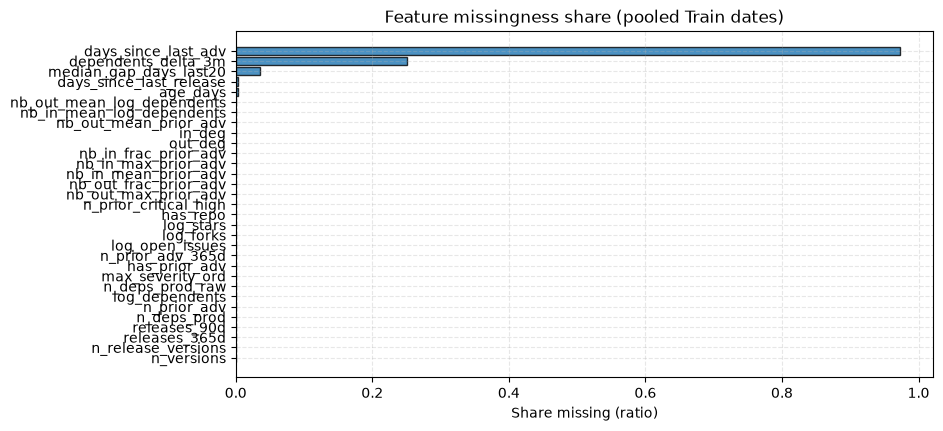

In [18]:
import matplotlib.pyplot as plt

# fig_01: Share missing per feature (horizontal bars, pooled train)
fig, ax = plt.subplots(figsize=(9, 4.5))
df_missing = df_dist_summary.sort_values(by='missing_share', ascending=True)
ax.barh(df_missing['feature'], df_missing['missing_share'], color='#1f77b4', edgecolor='black', alpha=0.8)
ax.set_xlabel('Share missing (ratio)')
ax.set_title('Feature missingness share (pooled Train dates)')
ax.grid(True, linestyle='--', alpha=0.3)
plt.savefig(FIG / 'fig_01_share_missing.png', bbox_inches='tight', dpi=150)
plt.show()


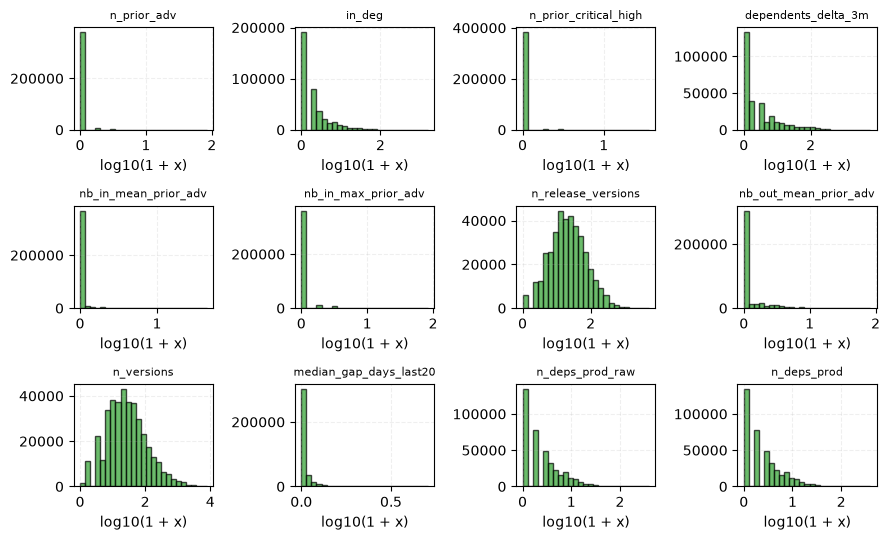

In [19]:
# fig_02: 12 feature histograms across groups with log10(1 + x) scaling
skew_sorted = df_dist_summary[~df_dist_summary['feature'].str.startswith('log_')].sort_values(by='skewness', ascending=False)
sample_12 = skew_sorted['feature'].head(12).tolist()

fig, axes = plt.subplots(3, 4, figsize=(9, 5.5))
axes = axes.flatten()
for idx, col in enumerate(sample_12):
    ax = axes[idx]
    vals = df_train_pooled[col].dropna()
    if (vals >= 0).all():
        ax.hist(np.log10(1 + vals), bins=25, color='#2ca02c', edgecolor='black', alpha=0.7)
        ax.set_xlabel('log10(1 + x)')
    else:
        ax.hist(vals, bins=25, color='#2ca02c', edgecolor='black', alpha=0.7)
    ax.set_title(col, fontsize=8)
    ax.grid(True, linestyle='--', alpha=0.2)
plt.tight_layout()
plt.savefig(FIG / 'fig_02_skewed_features_hist.png', bbox_inches='tight', dpi=150)
plt.show()


In [20]:
# Propose LOG1P_COLS for non-negative count features with skewness > 2
LOG1P_COLS = df_dist_summary[
    (df_dist_summary['skewness'] > 2.0) &
    (~df_dist_summary['feature'].str.startswith('log_')) &
    (df_dist_summary['min'] >= 0) &
    (~df_dist_summary['is_constant'])
]['feature'].tolist()
print("Proposed LOG1P_COLS:\n", LOG1P_COLS)

# Missingness co-occurrence correlation
na_cols = [c for c in num_cols if df_train_pooled[c].isna().any()]
df_na_corr = df_train_pooled[na_cols].isna().astype(float).corr()
print("\nMissingness co-occurrence correlation:\n", df_na_corr.round(3))


Proposed LOG1P_COLS:
 ['n_versions', 'n_release_versions', 'median_gap_days_last20', 'n_deps_prod', 'n_deps_prod_raw', 'dependents_delta_3m', 'n_prior_adv', 'has_prior_adv', 'max_severity_ord', 'n_prior_critical_high', 'out_deg', 'in_deg', 'nb_out_mean_prior_adv', 'nb_out_max_prior_adv', 'nb_out_frac_prior_adv', 'nb_in_mean_prior_adv', 'nb_in_max_prior_adv', 'nb_in_frac_prior_adv']

Missingness co-occurrence correlation:
                          age_days  days_since_last_release  \
age_days                    1.000                    1.000   
days_since_last_release     1.000                    1.000   
median_gap_days_last20      0.315                    0.315   
dependents_delta_3m         0.002                    0.002   
days_since_last_adv         0.010                    0.010   

                         median_gap_days_last20  dependents_delta_3m  \
age_days                                  0.315                0.002   
days_since_last_release                   0.315          

Highly correlated feature pairs (|rho| > 0.95): 15


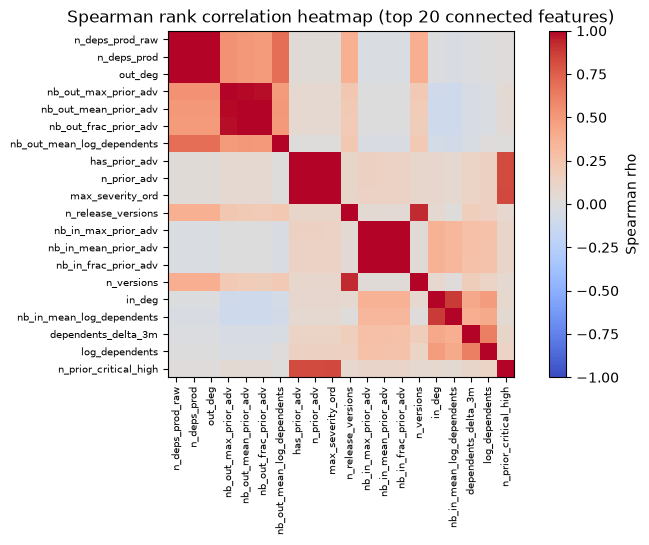

In [21]:
# Redundancy: Spearman correlation on sampled train rows and fig_03
sample_n = min(200000, len(df_train_pooled))
sample_corr_df = df_train_pooled[num_cols].sample(n=sample_n, random_state=SEED)
spearman_corr = sample_corr_df.corr(method='spearman')

high_corr_pairs = []
for i in range(len(num_cols)):
    for j in range(i + 1, len(num_cols)):
        r = spearman_corr.iloc[i, j]
        if abs(r) > 0.95:
            high_corr_pairs.append((num_cols[i], num_cols[j], float(r)))
print(f"Highly correlated feature pairs (|rho| > 0.95): {len(high_corr_pairs)}")

# fig_03: Correlation heatmap of top 20 connected features
top20_cols = spearman_corr.abs().mean().sort_values(ascending=False).head(20).index.tolist()
fig, ax = plt.subplots(figsize=(9, 4.5))
im = ax.imshow(spearman_corr.loc[top20_cols, top20_cols].values, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(im, ax=ax, label='Spearman rho')
ax.set_xticks(range(20)); ax.set_xticklabels(top20_cols, rotation=90, fontsize=7)
ax.set_yticks(range(20)); ax.set_yticklabels(top20_cols, fontsize=7)
ax.set_title('Spearman rank correlation heatmap (top 20 connected features)')
plt.savefig(FIG / 'fig_03_correlation_heatmap.png', bbox_inches='tight', dpi=150)
plt.show()


## Part E - Drift (Label-Free)

**Question:** Which features undergo distribution drift between Train and subsequent evaluation periods?
**How to read:** PSI compares quantile bins fitted on pooled Train rows. Values exceeding 0.25 indicate noticeable distribution shifts. Plots visualize PSI per feature and median monthly trajectories.


In [22]:
# Compute PSI for each evaluation split against pooled Train
val_pooled = pd.concat([pd.read_parquet(PROC / f"T={d}" / 'features.parquet') for d in val_dates], ignore_index=True)
test_a_pooled = pd.concat([pd.read_parquet(PROC / f"T={d}" / 'features.parquet') for d in test_a_grid['T'].dt.date.astype(str)], ignore_index=True)
test_b_pooled = pd.concat([pd.read_parquet(PROC / f"T={d}" / 'features.parquet') for d in test_b_grid['T'].dt.date.astype(str)], ignore_index=True)

psi_rows = []
for c in num_cols:
    t_v = df_train_pooled[c].values
    p_val = psi(t_v, val_pooled[c].values, bins=PSI_BINS)
    p_ta = psi(t_v, test_a_pooled[c].values, bins=PSI_BINS)
    p_tb = psi(t_v, test_b_pooled[c].values, bins=PSI_BINS)
    max_p = max([p for p in [p_val, p_ta, p_tb] if not np.isnan(p)], default=0.0)
    psi_rows.append({
        'feature': c, 'psi_val': p_val, 'psi_test_a': p_ta, 'psi_test_b': p_tb,
        'max_psi': max_p, 'drift_flag': (max_p > PSI_FLAG)
    })

df_psi = pd.DataFrame(psi_rows).sort_values(by='max_psi', ascending=False)
print("Top 8 drifting features by maximum PSI:\n", df_psi.head(8).to_string(index=False))


Top 8 drifting features by maximum PSI:
                   feature   psi_val  psi_test_a  psi_test_b   max_psi  drift_flag
  days_since_last_release 12.433856   12.433856   12.433856 12.433856        True
                 age_days 12.433856   12.433856   12.433856 12.433856        True
      days_since_last_adv 12.431378   12.431378   12.431378 12.431378        True
           log_dependents  4.793853    5.026782    6.038704  6.038704        True
nb_in_mean_log_dependents  1.629793    2.074512    2.670948  2.670948        True
       n_release_versions  0.584434    0.587228    0.569454  0.587228        True
               n_versions  0.569006    0.567540    0.549117  0.569006        True
                   in_deg  0.261248    0.255900    0.251749  0.261248        True


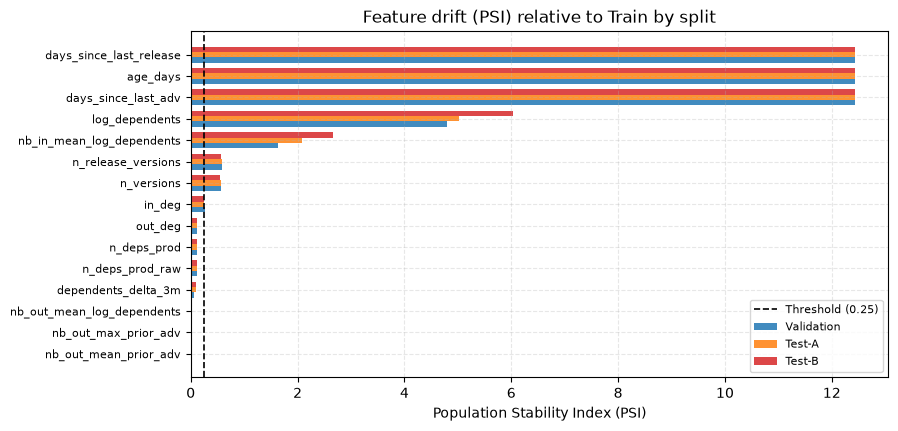

In [23]:
# fig_04: PSI per feature for val, test_a, and test_b
fig, ax = plt.subplots(figsize=(9, 4.5))
top_psi = df_psi.head(15).iloc[::-1]
y_p = np.arange(len(top_psi)); h = 0.25

ax.barh(y_p - h, top_psi['psi_val'], height=h, label='Validation', color='#1f77b4', alpha=0.85)
ax.barh(y_p, top_psi['psi_test_a'], height=h, label='Test-A', color='#ff7f0e', alpha=0.85)
ax.barh(y_p + h, top_psi['psi_test_b'], height=h, label='Test-B', color='#d62728', alpha=0.85)
ax.axvline(PSI_FLAG, color='black', linestyle='--', linewidth=1.2, label=f'Threshold ({PSI_FLAG})')
ax.set_yticks(y_p); ax.set_yticklabels(top_psi['feature'], fontsize=8)
ax.set_xlabel('Population Stability Index (PSI)')
ax.set_title('Feature drift (PSI) relative to Train by split')
ax.grid(True, linestyle='--', alpha=0.3); ax.legend(fontsize=8)
plt.savefig(FIG / 'fig_04_psi_by_split.png', bbox_inches='tight', dpi=150)
plt.show()


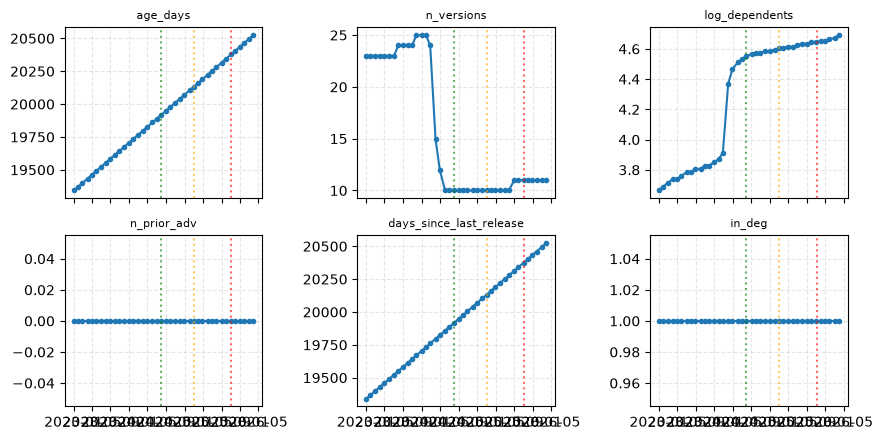

In [24]:
# fig_05: Monthly median trends of 6 key features with split boundaries
trend_cols = ['age_days', 'n_versions', 'log_dependents', 'n_prior_adv', 'days_since_last_release', 'in_deg']
monthly_records = []

for folder in t_folders:
    if folder.name == 'T=NOW': continue
    feats = pd.read_parquet(folder / 'features.parquet')
    meds = {c: float(feats[c].median()) for c in trend_cols if c in feats.columns}
    meds['date'] = pd.Timestamp(folder.name.replace('T=', ''))
    monthly_records.append(meds)

df_trends = pd.DataFrame(monthly_records).sort_values(by='date')
fig, axes = plt.subplots(2, 3, figsize=(9, 4.5), sharex=True)
axes = axes.flatten()

for idx, col in enumerate(trend_cols):
    ax = axes[idx]
    ax.plot(df_trends['date'], df_trends[col], marker='o', markersize=3, color='#1f77b4')
    ax.set_title(col, fontsize=8)
    ax.grid(True, linestyle='--', alpha=0.3)
    for split_df, col_c in [(val_grid, 'green'), (test_a_grid, 'orange'), (test_b_grid, 'red')]:
        ax.axvline(split_df['T'].min(), color=col_c, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig(FIG / 'fig_05_feature_trends_over_time.png', bbox_inches='tight', dpi=150)
plt.show()


**Note on PSI Interpretation:**

PSI measures changes in feature distributions across time. It does not imply that model discrimination or predictive power will degrade; it quantifies natural ecosystem progression (e.g., packages aging and accumulating release versions).


## Part F - Preprocessing Design (Fit on Train Only)

**Question:** Can feature preprocessing (log1p transform, missing flags, median imputation, standardization) be fitted strictly on Train and applied stably across splits?
**How to read:** Unit property tests verify invariant statistics, zero output NaNs, stable flag columns, and isolation from test splits.


In [25]:
# Partition features and fit Preprocessor on pooled Train rows
NUMERIC_NON_GRAPH = [c for c in num_cols if not any(c.startswith(p) for p in ['out_deg', 'in_deg', 'nb_'])]
NUMERIC_GRAPH = [c for c in num_cols if any(c.startswith(p) for p in ['out_deg', 'in_deg', 'nb_'])]

prep = Preprocessor(NUMERIC_NON_GRAPH, log1p_cols=LOG1P_COLS)
prep.fit(df_train_pooled)

print(f"Fitted Preprocessor on {len(df_train_pooled):,} train rows.")
print(f"Missingness flag columns: {len(prep.flag_cols_)} -> {prep.flag_cols_}")
print(f"Fitted medians (sample):\n{prep.median_.head(5)}")


Fitted Preprocessor on 390,000 train rows.
Missingness flag columns: 5 -> ['age_days', 'days_since_last_release', 'median_gap_days_last20', 'dependents_delta_3m', 'days_since_last_adv']
Fitted medians (sample):
age_days                   19524.707912
n_versions                     3.218876
n_release_versions             3.044522
days_since_last_release    19522.924740
releases_90d                   0.000000
dtype: float64


In [26]:
# Preprocessor invariant verification tests
# (a) Stored statistics immutable across transform calls
init_med = prep.median_.copy()
_ = prep.transform(val_pooled)
check("preprocessor invariant: stored statistics unchanged after transform", (prep.median_ == init_med).all())

# (b) Transformed train has mean ~ 0 and std ~ 1
X_tr = prep.transform(df_train_pooled)
mean_err = (X_tr[NUMERIC_NON_GRAPH].mean().abs() > 1e-5).sum()
check("preprocessor invariant: train transform has zero mean and unit variance", (mean_err == 0))

# (c) Zero NaN or Inf after transform
check("preprocessor invariant: zero NaN or Inf after transform", not np.isnan(X_tr.values).any() and not np.isinf(X_tr.values).any())

# (d) Fixed flag set preserved when transforming new frames
X_val = prep.transform(val_pooled)
check("preprocessor invariant: flag columns set strictly fixed at train fit", list(X_val.columns) == list(X_tr.columns))

# (e) Refitting on val produces distinct statistics
prep_val = Preprocessor(NUMERIC_NON_GRAPH, log1p_cols=LOG1P_COLS).fit(val_pooled)
check("preprocessor invariant: train-only fit produces distinct statistics from val fit", (prep_val.mean_ != prep.mean_).any())


PASS  preprocessor invariant: stored statistics unchanged after transform 
PASS  preprocessor invariant: train transform has zero mean and unit variance 
PASS  preprocessor invariant: zero NaN or Inf after transform 
PASS  preprocessor invariant: flag columns set strictly fixed at train fit 
PASS  preprocessor invariant: train-only fit produces distinct statistics from val fit 


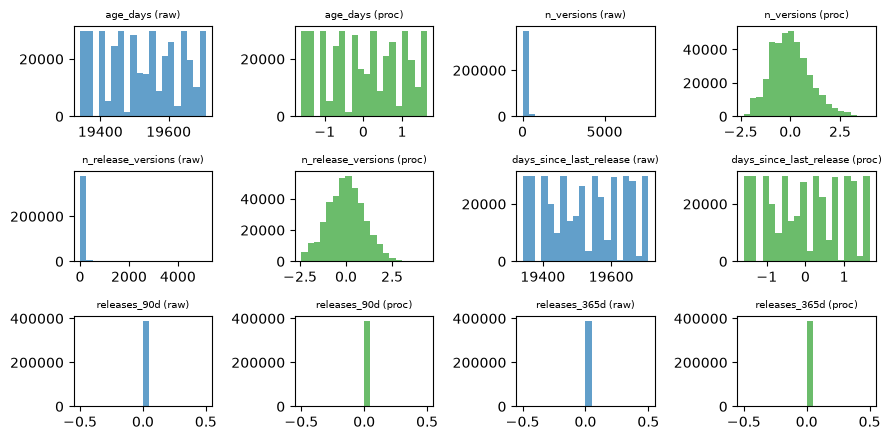

In [27]:
# fig_06: Histograms before and after transformation (Train)
sample_6 = NUMERIC_NON_GRAPH[:6]
fig, axes = plt.subplots(3, 4, figsize=(9, 4.5))

for idx, col in enumerate(sample_6):
    r, c = divmod(idx, 2)
    ax_raw = axes[r, c * 2]
    ax_tr = axes[r, c * 2 + 1]
    
    vals_raw = df_train_pooled[col].dropna()
    vals_tr = X_tr[col]
    
    ax_raw.hist(vals_raw, bins=20, color='#1f77b4', alpha=0.7)
    ax_raw.set_title(f"{col} (raw)", fontsize=7)
    ax_tr.hist(vals_tr, bins=20, color='#2ca02c', alpha=0.7)
    ax_tr.set_title(f"{col} (proc)", fontsize=7)

plt.tight_layout()
plt.savefig(FIG / 'fig_06_preprocessor_before_after.png', bbox_inches='tight', dpi=150)
plt.show()


## Part G - Labels Versus Features (Train and Val Dates ONLY)

**Question:** Which features provide true predictive signal for 6-month advisory risk on Train and Validation dates?
**How to read:** Evaluated strictly on Train and Val dates (Test splits excluded to prevent leakage). Tables display mean single-feature AUC and standard deviations across dates for all packages and the first-time subset.


In [28]:
# Verify test date exclusion and report base rates
eval_dates = train_dates + val_dates
assert not any(d in test_dates for d in eval_dates), "FATAL: Test dates found in label evaluation!"
print(f"Label analysis dates (train={len(train_dates)}, val={len(val_dates)}): {eval_dates}")

base_rates = []
for d in eval_dates:
    lbl = pd.read_parquet(PROC / f"T={d}" / 'labels.parquet')
    n_pos = int(lbl['label'].sum())
    base_rates.append({'T': d, 'n_nodes': len(lbl), 'positives': n_pos, 'base_rate': n_pos / len(lbl)})
df_base_rates = pd.DataFrame(base_rates)
print("Base rates (first 3 train, all val):\n", pd.concat([df_base_rates.head(3), df_base_rates.tail(len(val_dates))]).to_string(index=False))


Label analysis dates (train=13, val=2): ['2023-01-02', '2023-01-29', '2023-02-27', '2023-04-03', '2023-05-01', '2023-05-29', '2023-07-03', '2023-07-31', '2023-08-28', '2023-10-02', '2023-10-30', '2023-11-27', '2024-01-01', '2024-07-29', '2024-09-02']
Base rates (first 3 train, all val):
          T  n_nodes  positives  base_rate
2023-01-02    30000         95   0.003167
2023-01-29    30000         90   0.003000
2023-02-27    30000         80   0.002667
2024-07-29    30000         75   0.002500
2024-09-02    30000         81   0.002700


In [29]:
# Single-feature AUC across Train and Val dates
auc_records = []
for d in eval_dates:
    feats = pd.read_parquet(PROC / f"T={d}" / 'features.parquet')
    lbl = pd.read_parquet(PROC / f"T={d}" / 'labels.parquet')
    first_mask = (lbl['had_prior_advisory'] == False)
    
    for c in num_cols:
        a_all = auc_rank(feats[c], lbl['label'])
        a_first = auc_rank(feats.loc[first_mask, c], lbl.loc[first_mask, 'label'])
        auc_records.append({'T': d, 'feature': c, 'auc_all': a_all, 'auc_first_time': a_first})

df_auc_all = pd.DataFrame(auc_records)
df_auc_nongraph = df_auc_all[df_auc_all['feature'].isin(NUMERIC_NON_GRAPH)].groupby('feature').agg(
    auc_all_mean=('auc_all', 'mean'), auc_all_sd=('auc_all', 'std'),
    auc_first_mean=('auc_first_time', 'mean'), auc_first_sd=('auc_first_time', 'std')
).reset_index()

df_auc_nongraph['sort_key'] = (df_auc_nongraph['auc_first_mean'] - 0.5).abs()
df_auc_nongraph = df_auc_nongraph.sort_values(by='sort_key', ascending=False)
leakage_candidates = df_auc_nongraph[(df_auc_nongraph['auc_all_mean'] > 0.90) | (df_auc_nongraph['auc_all_mean'] < 0.10)]['feature'].tolist()
check("zero non-graph features exhibit extreme leakage AUC (|AUC-0.5| > 0.40)", len(leakage_candidates) == 0, detail=f"leakage={leakage_candidates}")
print("Top non-graph features on first-time subset:\n", df_auc_nongraph.head(8).to_string(index=False))


PASS  zero non-graph features exhibit extreme leakage AUC (|AUC-0.5| > 0.40) | leakage=[]
Top non-graph features on first-time subset:
                 feature  auc_all_mean  auc_all_sd  auc_first_mean  auc_first_sd  sort_key
    dependents_delta_3m      0.792686    0.028384        0.765251      0.038014  0.265251
             n_versions      0.778301    0.035272        0.727168      0.047019  0.227168
     n_release_versions      0.781146    0.045759        0.722935      0.062059  0.222935
days_since_last_release      0.243590    0.029582        0.281140      0.037646  0.218860
         log_dependents      0.724981    0.017506        0.675476      0.030765  0.175476
            n_deps_prod      0.593987    0.015503        0.592226      0.033250  0.092226
        n_deps_prod_raw      0.593987    0.015503        0.592226      0.033250  0.092226
 median_gap_days_last20      0.451594    0.022842        0.448724      0.047556  0.051276


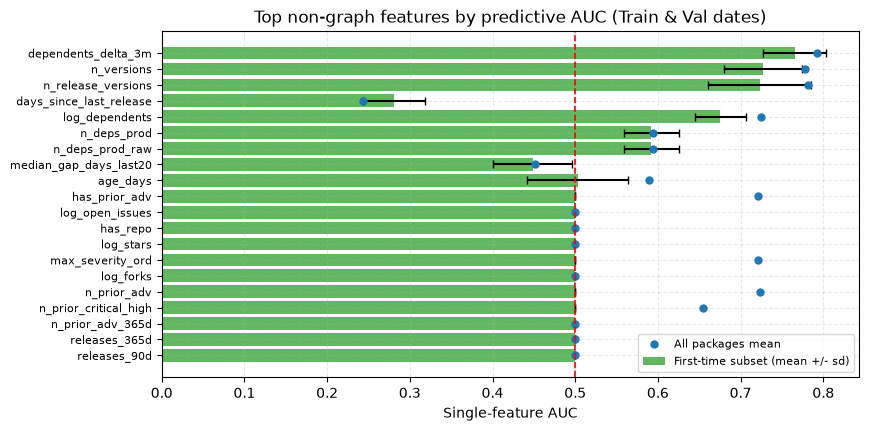

In [30]:
# fig_07: Top 20 features on first-time subset with error bars
top20_auc = df_auc_nongraph.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
y_pos = np.arange(len(top20_auc))

ax.barh(y_pos, top20_auc['auc_first_mean'], xerr=top20_auc['auc_first_sd'], color='#2ca02c', alpha=0.75,
        capsize=3, label='First-time subset (mean +/- sd)')
ax.plot(top20_auc['auc_all_mean'], y_pos, 'o', color='#1f77b4', markersize=5, label='All packages mean')
ax.axvline(0.5, color='red', linestyle='--', linewidth=1.2)
ax.set_yticks(y_pos); ax.set_yticklabels(top20_auc['feature'], fontsize=8)
ax.set_xlabel('Single-feature AUC')
ax.set_title('Top non-graph features by predictive AUC (Train & Val dates)')
ax.grid(True, linestyle='--', alpha=0.3); ax.legend(fontsize=8)
plt.savefig(FIG / 'fig_07_top20_feature_auc_train_val.png', bbox_inches='tight', dpi=150)
plt.show()


In [31]:
# Graph features predictive AUC table
df_auc_graph = df_auc_all[df_auc_all['feature'].isin(NUMERIC_GRAPH)].groupby('feature').agg(
    auc_all_mean=('auc_all', 'mean'), auc_all_sd=('auc_all', 'std'),
    auc_first_mean=('auc_first_time', 'mean'), auc_first_sd=('auc_first_time', 'std')
).reset_index().sort_values(by='auc_first_mean', ascending=False)
print("Graph features predictive AUC table (M3 features):\n", df_auc_graph.to_string(index=False))

# Reference heuristic baselines on Validation dates only
heuristics = []
for d in val_dates:
    feats = pd.read_parquet(PROC / f"T={d}" / 'features.parquet')
    lbl = pd.read_parquet(PROC / f"T={d}" / 'labels.parquet')
    f_mask = (lbl['had_prior_advisory'] == False)
    
    s_h1 = feats['n_prior_adv'].values + 1e-6 * feats['log_dependents'].values
    s_h2 = feats['log_dependents'].values
    s_h3 = feats['n_prior_adv_365d'].values
    
    heuristics.append({
        'T': d,
        'b1_all': auc_rank(s_h1, lbl['label']), 'b1_first': auc_rank(s_h1[f_mask], lbl.loc[f_mask, 'label']),
        'b2_all': auc_rank(s_h2, lbl['label']), 'b2_first': auc_rank(s_h2[f_mask], lbl.loc[f_mask, 'label']),
        'b3_all': auc_rank(s_h3, lbl['label']), 'b3_first': auc_rank(s_h3[f_mask], lbl.loc[f_mask, 'label']),
        'base_rate': float(lbl['label'].mean())
    })
df_heur = pd.DataFrame(heuristics)
print("\nReference heuristic baselines (Val dates only):\n", df_heur.mean(numeric_only=True).round(4).to_dict())


Graph features predictive AUC table (M3 features):
                    feature  auc_all_mean  auc_all_sd  auc_first_mean  auc_first_sd
       nb_in_max_prior_adv      0.626183    0.025112        0.606171      0.040412
      nb_in_mean_prior_adv      0.622901    0.025343        0.604701      0.040671
      nb_in_frac_prior_adv      0.621039    0.024671        0.603614      0.040305
                   out_deg      0.593987    0.015503        0.592226      0.033250
      nb_out_max_prior_adv      0.602959    0.022087        0.591116      0.020628
                    in_deg      0.621827    0.032428        0.585118      0.026893
 nb_in_mean_log_dependents      0.592815    0.025987        0.582725      0.032946
     nb_out_frac_prior_adv      0.591495    0.019853        0.582612      0.020659
     nb_out_mean_prior_adv      0.591742    0.020753        0.582439      0.020465
nb_out_mean_log_dependents      0.516095    0.012720        0.511527      0.035866

Reference heuristic baselines (Val

In [32]:
# Information overlap: Spearman correlation of graph features with core baselines
sample_gr = df_train_pooled[NUMERIC_GRAPH + ['log_dependents', 'n_prior_adv', 'in_deg']].sample(n=min(100000, len(df_train_pooled)), random_state=SEED)
corr_gr = sample_gr.corr(method='spearman')[['log_dependents', 'n_prior_adv', 'in_deg']].loc[NUMERIC_GRAPH]
print("Graph features correlation with core baselines:\n", corr_gr.round(3).to_string())

# Missingness vs label in pooled train
lbl_train_pooled = pd.concat([pd.read_parquet(PROC / f"T={d}" / 'labels.parquet') for d in train_dates], ignore_index=True)
miss_lbl_rows = []
for c in num_cols:
    if df_train_pooled[c].isna().any():
        m = df_train_pooled[c].isna()
        r_miss = float(lbl_train_pooled.loc[m, 'label'].mean()) if m.sum() > 0 else np.nan
        r_pres = float(lbl_train_pooled.loc[~m, 'label'].mean()) if (~m).sum() > 0 else np.nan
        miss_lbl_rows.append({'feature': c, 'n_missing': int(m.sum()), 'pos_rate_missing': r_miss, 'pos_rate_present': r_pres})
print("\nMissingness vs Label association (pooled train):\n", pd.DataFrame(miss_lbl_rows).to_string(index=False))


Graph features correlation with core baselines:
                             log_dependents  n_prior_adv  in_deg  in_deg
out_deg                             -0.007        0.023  -0.013  -0.013
in_deg                               0.483        0.085   1.000   1.000
in_deg                               0.483        0.085   1.000   1.000
nb_out_mean_prior_adv               -0.029        0.061  -0.103  -0.103
nb_out_max_prior_adv                -0.028        0.063  -0.101  -0.101
nb_out_frac_prior_adv               -0.028        0.062  -0.103  -0.103
nb_in_mean_prior_adv                 0.269        0.129   0.367   0.367
nb_in_max_prior_adv                  0.276        0.134   0.372   0.372
nb_in_frac_prior_adv                 0.268        0.128   0.366   0.366
nb_out_mean_log_dependents           0.009        0.009  -0.069  -0.069
nb_in_mean_log_dependents            0.416        0.058   0.880   0.880

Missingness vs Label association (pooled train):
                 feature  n_missing  

## Part H - Feature Sets and Summary

**Question:** Which verified feature sets are proposed for Tabular (M1/M2) and Graph (M3) models, and what is the comprehensive audit tally?
**How to read:** Lists define production candidate features. Results are serialized to `data/interim/feature_audit_summary.json`.


In [33]:
# Feature set definitions
constant_cols = df_dist_summary[df_dist_summary['is_constant']]['feature'].tolist()
heavy_nan_cols = df_dist_summary[df_dist_summary['missing_share'] > 0.50]['feature'].tolist()

EXCLUDED = []
for c in constant_cols:
    EXCLUDED.append({'feature': c, 'reason': 'constant across training dates'})
for c in set(heavy_nan_cols) - set(constant_cols):
    EXCLUDED.append({'feature': c, 'reason': 'heavy missingness (> 50%)'})

# Tabular features M1/M2: non-graph expected columns that passed checks and are non-constant
FEATURES_M1_M2 = [c for c in NUMERIC_NON_GRAPH if c not in constant_cols and c in ALL_EXPECTED]

# Graph augmented features M3: tabular plus graph neighbor aggregations
FEATURES_M3 = sorted(list(set(FEATURES_M1_M2 + [c for c in NUMERIC_GRAPH if c not in constant_cols and c in ALL_EXPECTED])))

print(f"FEATURES_M1_M2 ({len(FEATURES_M1_M2)} features): {FEATURES_M1_M2}")
print(f"FEATURES_M3 ({len(FEATURES_M3)} features): {FEATURES_M3}")
print(f"EXCLUDED ({len(EXCLUDED)} features): {EXCLUDED}")


FEATURES_M1_M2 (13 features): ['age_days', 'n_versions', 'n_release_versions', 'days_since_last_release', 'median_gap_days_last20', 'n_deps_prod', 'log_dependents', 'dependents_delta_3m', 'n_prior_adv', 'days_since_last_adv', 'has_prior_adv', 'max_severity_ord', 'n_prior_critical_high']
FEATURES_M3 (23 features): ['age_days', 'days_since_last_adv', 'days_since_last_release', 'dependents_delta_3m', 'has_prior_adv', 'in_deg', 'log_dependents', 'max_severity_ord', 'median_gap_days_last20', 'n_deps_prod', 'n_prior_adv', 'n_prior_critical_high', 'n_release_versions', 'n_versions', 'nb_in_frac_prior_adv', 'nb_in_max_prior_adv', 'nb_in_mean_log_dependents', 'nb_in_mean_prior_adv', 'nb_out_frac_prior_adv', 'nb_out_max_prior_adv', 'nb_out_mean_log_dependents', 'nb_out_mean_prior_adv', 'out_deg']
EXCLUDED (8 features): [{'feature': 'releases_90d', 'reason': 'constant across training dates'}, {'feature': 'releases_365d', 'reason': 'constant across training dates'}, {'feature': 'n_prior_adv_365d',

In [34]:
import json

def to_serializable(obj):
    if isinstance(obj, (np.integer, int)): return int(obj)
    if isinstance(obj, (np.floating, float)): return float(obj)
    if isinstance(obj, (np.bool_, bool)): return bool(obj)
    if isinstance(obj, (pd.Timestamp, pd.Timedelta)): return str(obj)
    raise TypeError(f"Type {type(obj)} not serializable")

audit_summary = {
    'results': [{'name': r[0], 'ok': r[1], 'detail': str(r[2])} for r in RESULTS],
    'per_date_summary': df_per_date_overview.to_dict(orient='records'),
    'recomputation': df_recomp_summary.to_dict(orient='records'),
    'psi_table': df_psi.to_dict(orient='records'),
    'auc_tables': {
        'non_graph': df_auc_nongraph.to_dict(orient='records'),
        'graph': df_auc_graph.to_dict(orient='records'),
        'heuristics': df_heur.to_dict(orient='records')
    },
    'feature_sets': {
        'FEATURES_M1_M2': FEATURES_M1_M2,
        'FEATURES_M3': FEATURES_M3,
        'EXCLUDED': EXCLUDED
    },
    'preprocessing': {
        'medians': prep.median_.to_dict(),
        'means': prep.mean_.to_dict(),
        'stds': prep.std_.to_dict(),
        'flag_cols': prep.flag_cols_,
        'log1p_cols': list(prep.log1p_cols)
    }
}

summary_path = DATA / 'interim' / 'feature_audit_summary.json'
with open(summary_path, 'w', encoding='utf-8') as f:
    json.dump(audit_summary, f, indent=2, default=to_serializable)

print(f"Serialized audit summary to {summary_path} ({summary_path.stat().st_size:,} bytes)")


Serialized audit summary to D:\DepRadar\data\interim\feature_audit_summary.json (34,544 bytes)


In [35]:
figures = sorted(FIG.glob('fig_*.png'))
print(f"\nGenerated figures ({len(figures)} total in {FIG}):")
for f in figures:
    print(f"  {f.name} ({f.stat().st_size / 1024:.1f} KB)")

pass_cnt = sum(1 for r in RESULTS if r[1])
fail_cnt = sum(1 for r in RESULTS if not r[1])
print(f"\nAudit checks tally: {pass_cnt} PASSED, {fail_cnt} FAILED (total {len(RESULTS)})")
if fail_cnt > 0:
    print("Failing checks:")
    for r in RESULTS:
        if not r[1]:
            print(f"  FAIL: {r[0]} | {r[2]}")



Generated figures (7 total in D:\DepRadar\docs\figures\eda_features):
  fig_01_share_missing.png (103.3 KB)
  fig_02_skewed_features_hist.png (88.9 KB)
  fig_03_correlation_heatmap.png (99.0 KB)
  fig_04_psi_by_split.png (65.3 KB)
  fig_05_feature_trends_over_time.png (89.4 KB)
  fig_06_preprocessor_before_after.png (60.8 KB)
  fig_07_top20_feature_auc_train_val.png (86.9 KB)

Audit checks tally: 50 PASSED, 1 FAILED (total 51)
Failing checks:
  FAIL: range check: n_versions >= 1 | violations=134609, examples=['@fortawesome/pro-solid-svg-icons', '@fortawesome/pro-light-svg-icons', '@fortawesome/pro-regular-svg-icons', '@microchip/scf-common', '@microchip/scf-device']


# Findings (fill in after running)

- **Failed range checks:**
  - [ ] 
- **Recomputation mismatches:**
  - [ ] 
- **Leakage tests:**
  - [ ] 
- **Features with heavy missingness or no variation:**
  - [ ] 
- **The strongest drift:**
  - [ ] 
- **log1p list:**
  - [ ] 
- **Correlated groups to prune:**
  - [ ] 
- **Suspicious features:**
  - [ ] 
- **First-time-subset signals:**
  - [ ] 
- **Feature sets to use:**
  - [ ] 
- **Decisions for the spec:**
  - [ ]
